# Display a HE Birghtfield OME-TIFF image

This tutorial walks through the `OpenOME` reader of `cosmix.bioformats`:

1. open a slide and inspect its metadata,
2. navigate the resolution pyramid,
3. display rgb image,
4. read regions at different levels,

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import ImageColor

from cosmix.bioformats.reader import get_slide_reader

## 1. Open the slide and inspect its metadata

In [3]:
SLIDE_PATH = "/cluster/CBIO/data1/mblons/orion/data/SURGEN/WSI/SR386_WSIs_ome/SR386_40X_HE_T001_01.ome.tiff"

slide = get_slide_reader(SLIDE_PATH)
print(slide)

OpenOME(name='SR386_40X_HE_T001_01', dimensions=(63758, 40190), channels=3, levels=8, mpp=0.5)


In [5]:
print(f"is multiplex: {slide.is_multiplex}")
print(f"is rgb: {slide.is_rgb}")
print(f"mpp: {slide.mpp}")
print(f"mag: {slide.magnification}")
print(f"dimensions: {slide.dimensions}")
print(f"format: {slide.format}")
print(f"pages: {slide.pages}")
print(f"channels: {slide.channel_count}")
print(f"names: {slide.channel_names}")

is multiplex: False
is rgb: True
mpp: 0.5
mag: 20
dimensions: (63758, 40190)
format: uchar
pages: 1
channels: 3
names: None


The raw `Pixels` attributes of the OME-XML are available with `get_pixels_metadata`.

In [6]:
slide.get_pixels_metadata()

{'size_x': 63758,
 'size_y': 40190,
 'size_z': 1,
 'size_c': 3,
 'size_t': 1,
 'type': 'uint8',
 'dimension_order': 'XYCZT',
 'physical_size_x': 0.5,
 'physical_size_y': 0.5,
 'physical_size_unit': 'µm'}

A user-provided `mpp` takes precedence over the OME-XML `PhysicalSizeX`.

In [7]:
slide_mpp = get_slide_reader(SLIDE_PATH, mpp=0.25)
print(f"OME mpp: {slide.mpp} -> mag {slide.magnification}")
print(f"user mpp: {slide_mpp.mpp} -> mag {slide_mpp.magnification}")

OME mpp: 0.5 -> mag 20
user mpp: 0.25 -> mag 40


## 2. Resolution pyramid

In [8]:
print(f"level count: {slide.level_count}")
for level, (dims, downsample) in enumerate(
    zip(slide.level_dimensions, slide.level_downsamples)
):
    print(f"level {level}: {dims}, downsample {downsample:.2f}")

level count: 8
level 0: (63758, 40190), downsample 1.00
level 1: (31879, 20095), downsample 2.00
level 2: (15939, 10047), downsample 4.00
level 3: (7969, 5023), downsample 8.00
level 4: (3984, 2511), downsample 16.01
level 5: (1992, 1255), downsample 32.02
level 6: (996, 627), downsample 64.10
level 7: (498, 313), downsample 128.40


`get_best_level_for_downsample` returns `(level, level_downsample, resize_factor)`:
an exact match needs no resize, otherwise the closest finer level is returned
with the factor to apply on top of it.

In [9]:
for ask_downsample in [1, 4, 6, 1000]:
    level, level_downsample, resize_factor = slide.get_best_level_for_downsample(
        ask_downsample
    )
    print(
        f"downsample {ask_downsample}: level {level} "
        f"(downsample {level_downsample:.2f}), resize factor {resize_factor:.3f}"
    )

downsample 1: level 0 (downsample 1.00), resize factor 1.000
downsample 4: level 2 (downsample 4.00), resize factor 1.000
downsample 6: level 2 (downsample 4.00), resize factor 0.667
downsample 1000: level 7 (downsample 128.40), resize factor 0.128


## 3. Display thumbnails

`get_thumbnail` reads rgb channels.

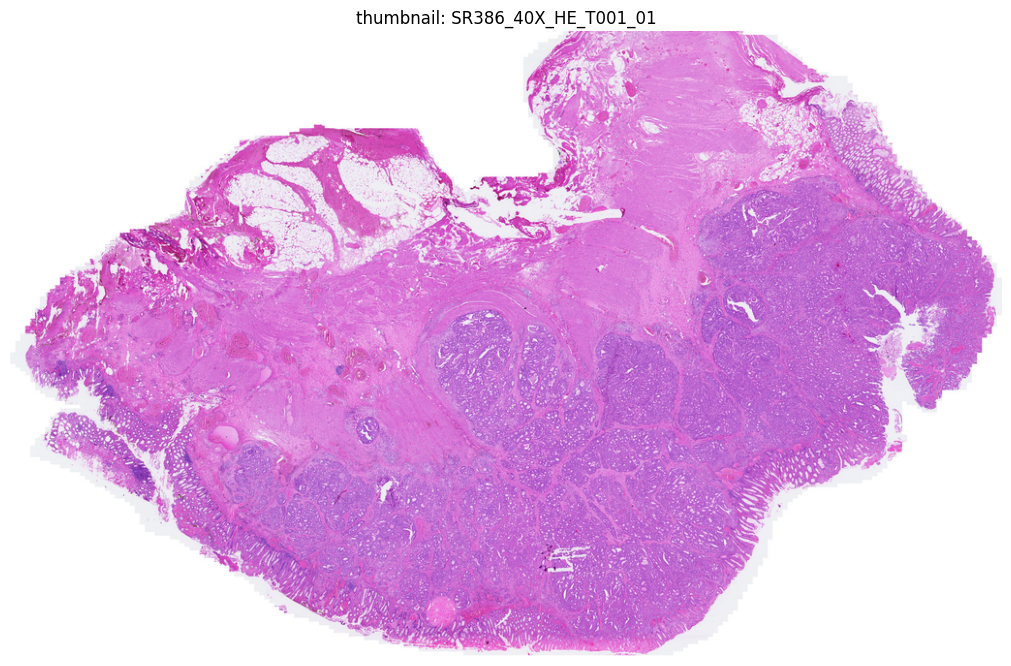

In [12]:
thumbnail = slide.get_thumbnail(size=(1024, 1024), numpy=True)
fig, ax = plt.subplots(1, 1, figsize=(10, 10), layout="constrained")
ax.imshow(thumbnail, aspect="equal")
ax.set_title(f"thumbnail: {slide.name}")
ax.set_axis_off()
plt.show()

## 5. Read a region

`location` is always given in level 0 `(x, y)` coordinates, whatever the `level`.
Here it is placed at the center of the tissue, detected on the Hoechst thumbnail.

level 4: (2511, 3984, 3), uint8
tissue center (level 0): (29194, 17766)
level 0: location (28682, 17254), shape (1024, 1024, 3)
level 2: location (27145, 15717), shape (1024, 1024, 3)


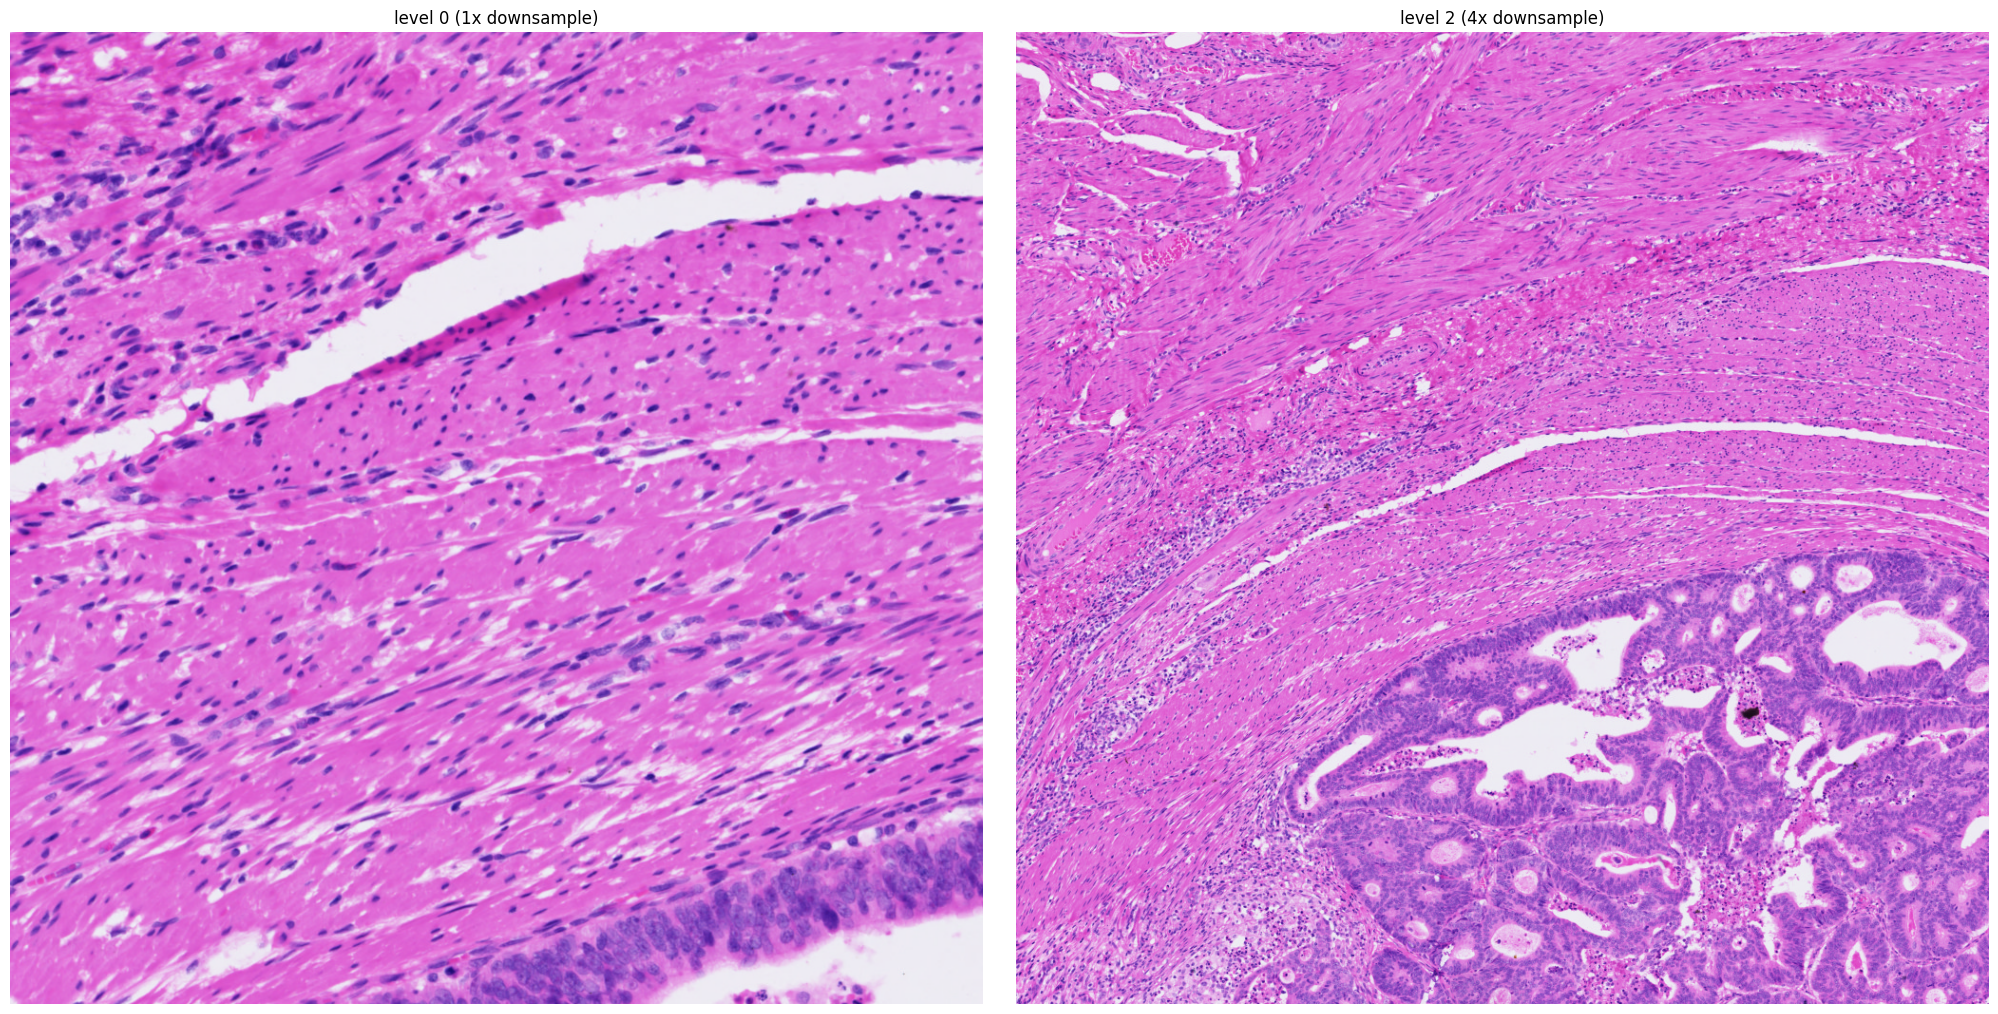

In [ ]:
level = slide.get_best_level_for_downsample(32)[0]
rgb = slide.read_whole(level=level)
print(f"level {level}: {rgb.shape}, {rgb.dtype}")

ys, xs, _ = np.nonzero(rgb > rgb.mean())
downsample = slide.level_downsamples[level]

center = (int(np.median(xs) * downsample), int(np.median(ys) * downsample))
print(f"tissue center (level 0): {center}")

region_size = (1024, 1024)
regions = {}
for region_level in [0, 2]:
    # shift the location so that the region is centered on `center`
    half = [s * slide.level_downsamples[region_level] / 2 for s in region_size]
    location = (int(center[0] - half[0]), int(center[1] - half[1]))
    regions[region_level] = slide.read_region(
        location, level=region_level, size=region_size
    )
    print(
        f"level {region_level}: location {location}, shape {regions[region_level].shape}"
    )

fig, ax = plt.subplots(
    1, len(regions), figsize=(10 * len(regions), 10), layout="constrained"
)
for i, (region_level, region) in enumerate(regions.items()):
    ax[i].imshow(regions[region_level])
    ax[i].set_title(
        f"level {region_level} ({slide.level_downsamples[region_level]:.0f}x downsample)"
    )
    ax[i].set_axis_off()
plt.show()

A region crossing the image border is cropped (with a warning).

In [ ]:
width_0, height_0 = slide.dimensions
border_region = slide.read_region(
    (width_0 - 300, height_0 - 200), level=0, size=(1024, 1024)
)
print(f"border region shape: {border_region.shape}")

region is out of image bounds 63758 x 40190, size was cropped


border region shape: (200, 300, 3)


## 6. Invalid inputs

In [ ]:
lowest = slide.read_whole(level=99)
print(
    f"level 99 -> shape {lowest.shape}, level {slide.level_count - 1} dims {slide.level_dimensions[-1]}"
)

level 99 does not exist, set to lowest resolution level 7


level 99 -> shape (313, 498, 3), level 7 dims (498, 313)


The other invalid inputs raise explicit errors.

In [ ]:
invalid_calls = {
    "multiplex thumbnail as PIL": lambda: slide.get_thumbnail(),
    "thumbnail without channel": lambda: slide.get_single_channel_thumbnail(),
    "unknown channel name": lambda: slide.get_channel_index("CD99"),
    "region outside the image": lambda: slide.read_region(
        (width_0 + 10, 0), level=0, size=(64, 64)
    ),
    "negative level": lambda: slide.read_whole(level=-1),
    "non OME-TIFF file": lambda: get_slide_reader("slide.svs"),
}
for description, call in invalid_calls.items():
    try:
        call()
        print(f"{description}: no error")
    except Exception as error:
        print(f"{description}: {type(error).__name__}: {error}")

multiplex thumbnail as PIL: no error
thumbnail without channel: TypeError: Single channel display is only supported for multiplex images
unknown channel name: KeyError: "`key`='CD99' is not a channel name, expected one of None"
region outside the image: ValueError: `location`=(63768, 0) is outside the image at level 0 (63758 x 40190)
negative level: ValueError: `level` must be >= 0, got -1
non OME-TIFF file: ValueError: `img_path`=slide.svs is not supported, expected an OME-TIFF (`.ome.tif` or `.ome.tiff`).
